# Animal Species Classification Using Machine Learning and Deep Learning

Python / Google Colab | Animals-10 dataset | Ten-class image classification

The dataset is not bundled. See the repository README for download and Google Drive setup.


## Setup and dataset loading

The original notebook runs in Google Colab and loads the Animals-10 archive from Google Drive.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

zip_path = "/content/drive/MyDrive/animal_class/archive.zip"

print("File exists:", os.path.exists(zip_path))
print("File path:", zip_path)

File exists: True
File path: /content/drive/MyDrive/animal_class/archive.zip


In [3]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/animal_class/archive.zip"
extract_path = "/content/animals10"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction finished.")
print(os.listdir(extract_path))

Extraction finished.
['translate.py', 'raw-img']


In [4]:
for root, dirs, files in os.walk("/content/animals10"):
    print("Root:", root)
    print("Folders:", dirs[:20])
    print("Number of files:", len(files))
    break

Root: /content/animals10
Folders: ['raw-img']
Number of files: 1


In [5]:
import os

data_dir = "/content/animals10/raw-img"

print("Folders inside raw-img:")
print(os.listdir(data_dir))

Folders inside raw-img:
['cane', 'elefante', 'mucca', 'farfalla', 'cavallo', 'gallina', 'ragno', 'pecora', 'scoiattolo', 'gatto']


## Dataset exploration and preprocessing

Translate category names, inspect image distributions, balance the classes and create train/validation/test splits.


In [6]:
import os
import pandas as pd

data_dir = "/content/animals10/raw-img"

label_translation = {
    "cane": "dog",
    "cavallo": "horse",
    "elefante": "elephant",
    "farfalla": "butterfly",
    "gallina": "chicken",
    "gatto": "cat",
    "mucca": "cow",
    "pecora": "sheep",
    "ragno": "spider",
    "scoiattolo": "squirrel"
}

image_paths = []
labels = []

for folder_name in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder_name)

    if os.path.isdir(folder_path):
        label = label_translation.get(folder_name, folder_name)

        for file_name in os.listdir(folder_path):
            if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
                image_paths.append(os.path.join(folder_path, file_name))
                labels.append(label)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

                                          image_path label
0  /content/animals10/raw-img/cane/OIP-713M2pANCh...   dog
1  /content/animals10/raw-img/cane/OIP-4mbwSxNgGz...   dog
2  /content/animals10/raw-img/cane/OIP-DSB_aqrsck...   dog
3  /content/animals10/raw-img/cane/OIP-hvR-M9Q6x7...   dog
4  /content/animals10/raw-img/cane/OIP-lxdbeexOWd...   dog

Dataset shape: (26179, 2)

Class distribution:
label
dog          4863
spider       4821
chicken      3098
horse        2623
butterfly    2112
cow          1866
squirrel     1862
sheep        1820
cat          1668
elephant     1446
Name: count, dtype: int64


Dataset shape: (26179, 2)

Missing values:
image_path    0
label         0
dtype: int64

Class distribution:
label
dog          4863
spider       4821
chicken      3098
horse        2623
butterfly    2112
cow          1866
squirrel     1862
sheep        1820
cat          1668
elephant     1446
Name: count, dtype: int64


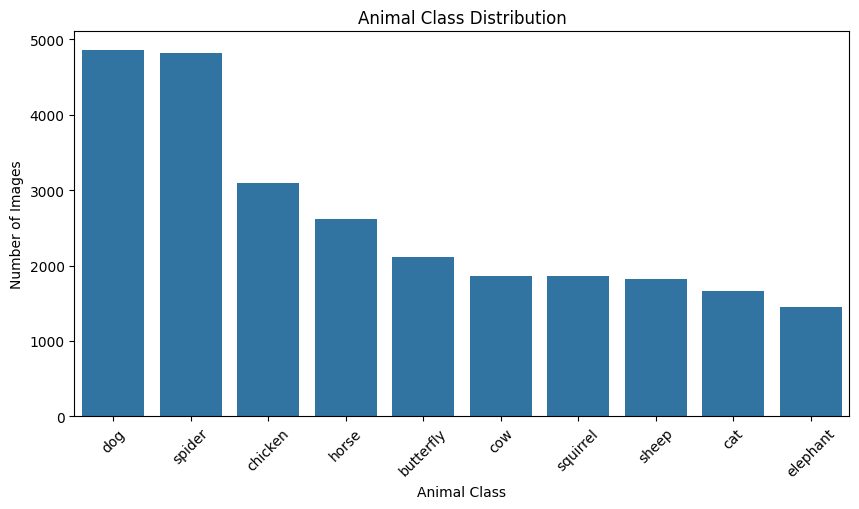

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="label", order=df["label"].value_counts().index)
plt.title("Animal Class Distribution")
plt.xlabel("Animal Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

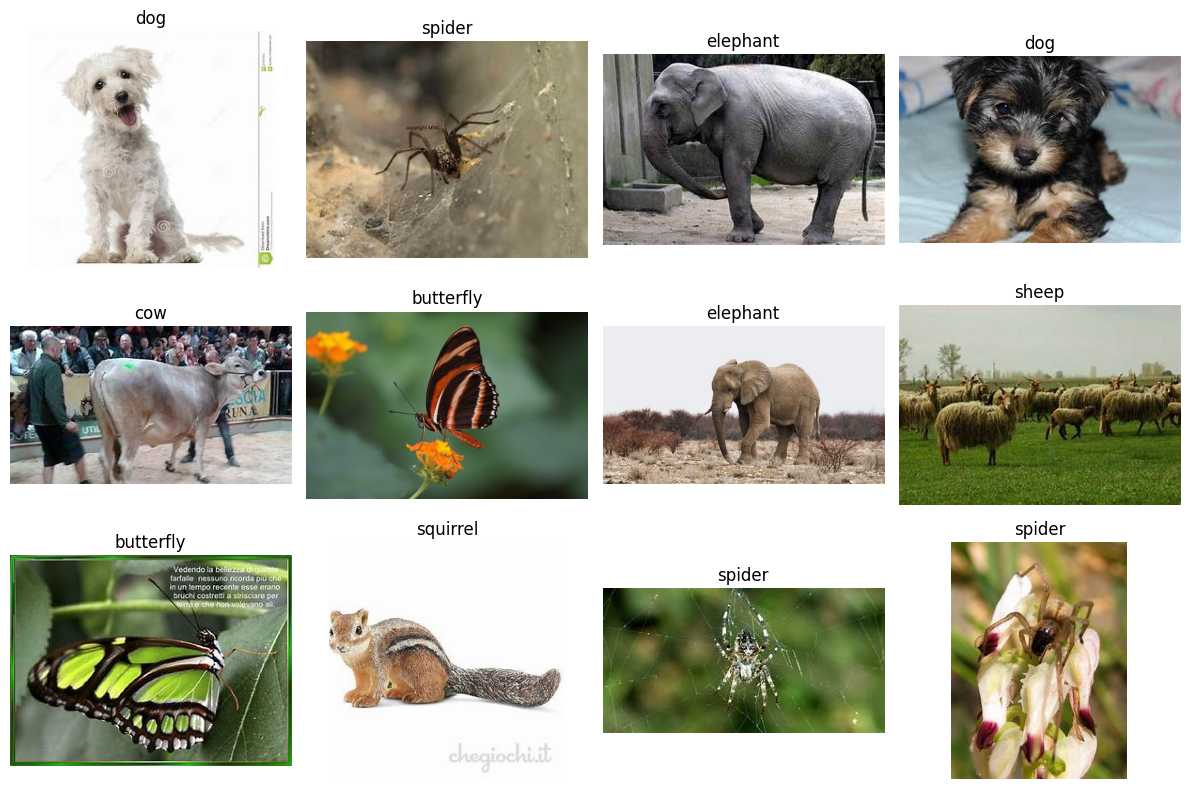

In [8]:
from PIL import Image
import random

sample_df = df.sample(12, random_state=42)

plt.figure(figsize=(12, 8))

for i, row in enumerate(sample_df.itertuples(), 1):
    img = Image.open(row.image_path).convert("RGB")
    plt.subplot(3, 4, i)
    plt.imshow(img)
    plt.title(row.label)
    plt.axis("off")

plt.tight_layout()
plt.show()

             width       height
count  1000.000000  1000.000000
mean    321.507000   251.178000
std     139.989789   157.280436
min     150.000000   106.000000
25%     300.000000   200.000000
50%     300.000000   225.000000
75%     300.000000   300.000000
max    3456.000000  4608.000000


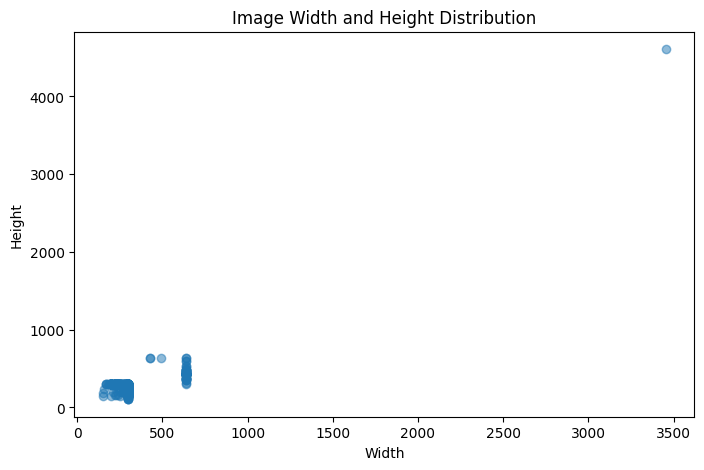

In [9]:
image_widths = []
image_heights = []

for path in df["image_path"].sample(1000, random_state=42):
    img = Image.open(path)
    image_widths.append(img.size[0])
    image_heights.append(img.size[1])

size_df = pd.DataFrame({
    "width": image_widths,
    "height": image_heights
})

print(size_df.describe())

plt.figure(figsize=(8, 5))
plt.scatter(size_df["width"], size_df["height"], alpha=0.5)
plt.title("Image Width and Height Distribution")
plt.xlabel("Width")
plt.ylabel("Height")
plt.show()

In [10]:
balanced_df = (
    df.groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=1000, random_state=42))
    .reset_index(drop=True)
)

print("Balanced dataset shape:", balanced_df.shape)
print(balanced_df["label"].value_counts())

Balanced dataset shape: (10000, 2)
label
butterfly    1000
cat          1000
chicken      1000
cow          1000
dog          1000
elephant     1000
horse        1000
sheep        1000
spider       1000
squirrel     1000
Name: count, dtype: int64


/tmp/ipykernel_943/3676331319.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=1000, random_state=42))


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
balanced_df["label_encoded"] = label_encoder.fit_transform(balanced_df["label"])

class_names = list(label_encoder.classes_)
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

train_df, temp_df = train_test_split(
    balanced_df,
    test_size=0.30,
    stratify=balanced_df["label_encoded"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_encoded"],
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Classes: ['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']
Number of classes: 10
Train: (7000, 3)
Validation: (1500, 3)
Test: (1500, 3)


## Image loading and baseline models

Prepare 32 x 32 RGB images, then train and evaluate the multilayer perceptron.


In [12]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array, to_categorical
from tqdm import tqdm

def load_images_from_dataframe(input_df, image_size):
    images = []
    labels = []
    skipped = 0

    for row in tqdm(input_df.itertuples(), total=len(input_df)):
        try:
            img = load_img(row.image_path, target_size=image_size)
            img_array = img_to_array(img)
            img_array = img_array / 255.0

            images.append(img_array)
            labels.append(row.label_encoded)

        except Exception:
            skipped += 1

    images = np.array(images, dtype="float32")
    labels = np.array(labels, dtype="int32")

    print("Loaded images:", images.shape)
    print("Loaded labels:", labels.shape)
    print("Skipped images:", skipped)

    return images, labels

In [14]:
small_image_size = (32, 32)

X_train_small, y_train = load_images_from_dataframe(train_df, small_image_size)
X_val_small, y_val = load_images_from_dataframe(val_df, small_image_size)
X_test_small, y_test = load_images_from_dataframe(test_df, small_image_size)

X_train_flat = X_train_small.reshape(X_train_small.shape[0], -1)
X_val_flat = X_val_small.reshape(X_val_small.shape[0], -1)
X_test_flat = X_test_small.reshape(X_test_small.shape[0], -1)

y_train_cat = to_categorical(y_train, num_classes)
y_val_cat = to_categorical(y_val, num_classes)
y_test_cat = to_categorical(y_test, num_classes)

print("Flat training shape:", X_train_flat.shape)
print("Flat validation shape:", X_val_flat.shape)
print("Flat test shape:", X_test_flat.shape)

100%|██████████| 7000/7000 [00:08<00:00, 859.12it/s]


Loaded images: (7000, 32, 32, 3)
Loaded labels: (7000,)
Skipped images: 0


100%|██████████| 1500/1500 [00:02<00:00, 691.91it/s]


Loaded images: (1500, 32, 32, 3)
Loaded labels: (1500,)
Skipped images: 0


100%|██████████| 1500/1500 [00:01<00:00, 1020.18it/s]

Loaded images: (1500, 32, 32, 3)
Loaded labels: (1500,)
Skipped images: 0
Flat training shape: (7000, 3072)
Flat validation shape: (1500, 3072)
Flat test shape: (1500, 3072)


In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

mlp_model = Sequential([
    Dense(15, activation="relu", input_shape=(X_train_flat.shape[1],)),
    Dense(25, activation="relu"),
    Dense(25, activation="relu"),
    Dense(20, activation="relu"),
    Dense(num_classes, activation="softmax")
])

mlp_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mlp_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 15)             │        46,095 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,875 (187.01 KB)

 Trainable params: 47,875 (187.01 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
mlp_history = mlp_model.fit(
    X_train_flat,
    y_train_cat,
    validation_data=(X_val_flat, y_val_cat),
    epochs=20,
    batch_size=64,
    verbose=1
)

Epoch 1/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.1173 - loss: 2.2992 - val_accuracy: 0.1260 - val_loss: 2.2901
Epoch 2/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1256 - loss: 2.2799 - val_accuracy: 0.1233 - val_loss: 2.2774
Epoch 3/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1377 - loss: 2.2686 - val_accuracy: 0.1453 - val_loss: 2.2750
Epoch 4/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1476 - loss: 2.2587 - val_accuracy: 0.1513 - val_loss: 2.2641
Epoch 5/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1520 - loss: 2.2478 - val_accuracy: 0.1467 - val_loss: 2.2578
Epoch 6/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1534 - loss: 2.2432 - val_accuracy: 0.1520 - val_loss: 2.2489
Epoch 7/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1551 - loss: 2.2328 - val_accuracy: 0.1480 - val_loss: 2.2452
Epoch 8/20
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1580 - loss: 2.2297 - val_accuracy: 0

In [17]:
mlp_test_loss, mlp_test_accuracy = mlp_model.evaluate(X_test_flat, y_test_cat, verbose=0)

print("MLP Test Loss:", mlp_test_loss)
print("MLP Test Accuracy:", mlp_test_accuracy)

MLP Test Loss: 2.212939739227295
MLP Test Accuracy: 0.15800000727176666


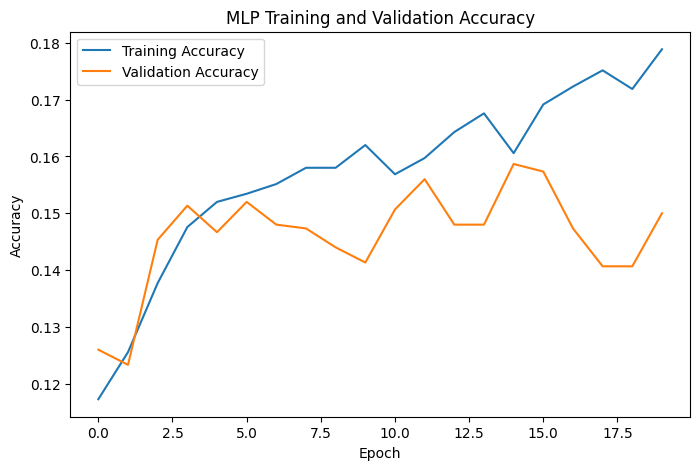

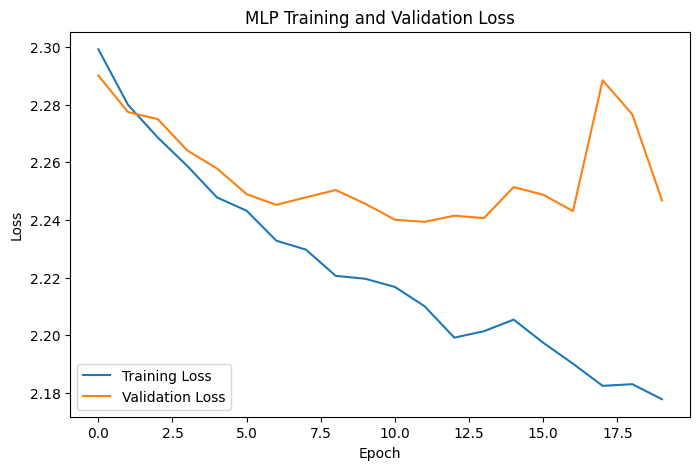

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(mlp_history.history["accuracy"], label="Training Accuracy")
plt.plot(mlp_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(mlp_history.history["loss"], label="Training Loss")
plt.plot(mlp_history.history["val_loss"], label="Validation Loss")
plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Random Forest classifier

Compare an ensemble learning baseline using flattened RGB pixels.


In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=25,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_flat, y_train)

rf_val_predictions = rf_model.predict(X_val_flat)
rf_test_predictions = rf_model.predict(X_test_flat)

rf_val_accuracy = accuracy_score(y_val, rf_val_predictions)
rf_test_accuracy = accuracy_score(y_test, rf_test_predictions)

print("Random Forest Validation Accuracy:", rf_val_accuracy)
print("Random Forest Test Accuracy:", rf_test_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, rf_test_predictions, target_names=class_names))

Random Forest Validation Accuracy: 0.352
Random Forest Test Accuracy: 0.3566666666666667

Classification Report:
              precision    recall  f1-score   support

   butterfly       0.46      0.51      0.48       150
         cat       0.31      0.35      0.33       150
     chicken       0.28      0.25      0.27       150
         cow       0.39      0.35      0.37       150
         dog       0.22      0.13      0.16       150
    elephant       0.39      0.38      0.39       150
       horse       0.44      0.37      0.40       150
       sheep       0.36      0.47      0.40       150
      spider       0.42      0.45      0.43       150
    squirrel       0.26      0.31      0.28       150

    accuracy                           0.36      1500
   macro avg       0.35      0.36      0.35      1500
weighted avg       0.35      0.36      0.35      1500



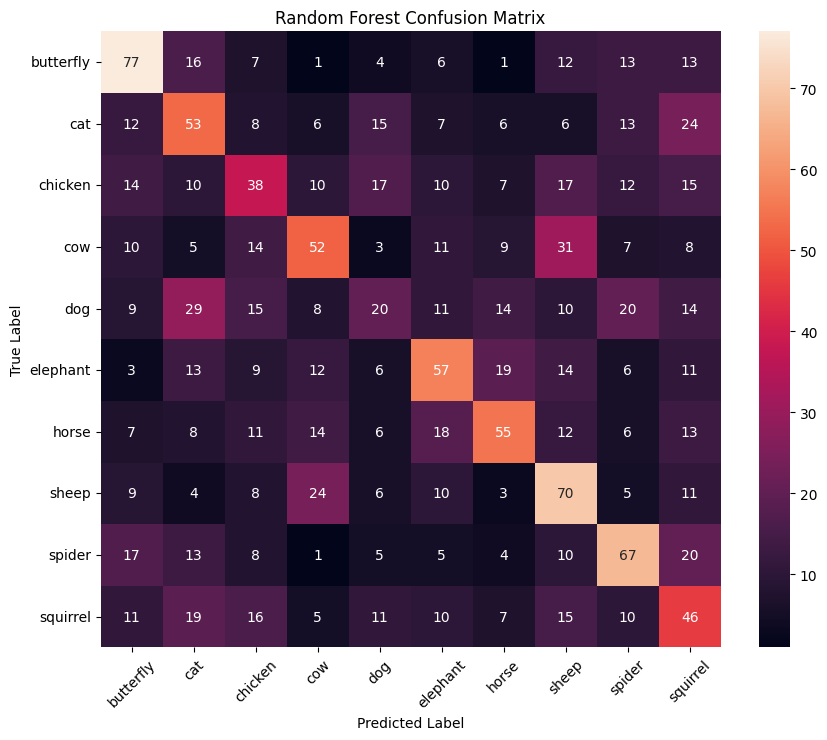

In [20]:
cm = confusion_matrix(y_test, rf_test_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [21]:
results = pd.DataFrame({
    "Model": ["MLP", "Random Forest"],
    "Test Accuracy": [mlp_test_accuracy, rf_test_accuracy]
})

results

,Model,Test Accuracy
0,MLP,0.158000
1,Random Forest,0.356667


## Convolutional neural network

Train and evaluate a CNN that preserves image spatial structure.


In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam

cnn_model = Sequential([
    Conv2D(32, (3, 3), activation="relu", padding="same", input_shape=(32, 32, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dropout(0.5),
    Dense(256, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 376,138 (1.43 MB)

 Trainable params: 375,434 (1.43 MB)

 Non-trainable params: 704 (2.75 KB)

In [23]:
cnn_history = cnn_model.fit(
    X_train_small,
    y_train_cat,
    validation_data=(X_val_small, y_val_cat),
    epochs=25,
    batch_size=64,
    verbose=1
)

Epoch 1/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 19s 75ms/step - accuracy: 0.2024 - loss: 2.4763 - val_accuracy: 0.1000 - val_loss: 4.9143
Epoch 2/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3164 - loss: 1.9238 - val_accuracy: 0.1027 - val_loss: 4.5930
Epoch 3/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3844 - loss: 1.7520 - val_accuracy: 0.2133 - val_loss: 2.6558
Epoch 4/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4286 - loss: 1.6113 - val_accuracy: 0.3533 - val_loss: 1.8495
Epoch 5/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4643 - loss: 1.5066 - val_accuracy: 0.4073 - val_loss: 1.6736
Epoch 6/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5047 - loss: 1.3883 - val_accuracy: 0.4113 - val_loss: 1.8513
Epoch 7/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5424 - loss: 1.2964 - val_accuracy: 0.4580 - val_loss: 1.6027
Epoch 8/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5746 - loss: 1.2172 - val_accuracy: 

In [24]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(X_test_small, y_test_cat, verbose=0)

print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy)

CNN Test Loss: 2.0627551078796387
CNN Test Accuracy: 0.5419999957084656


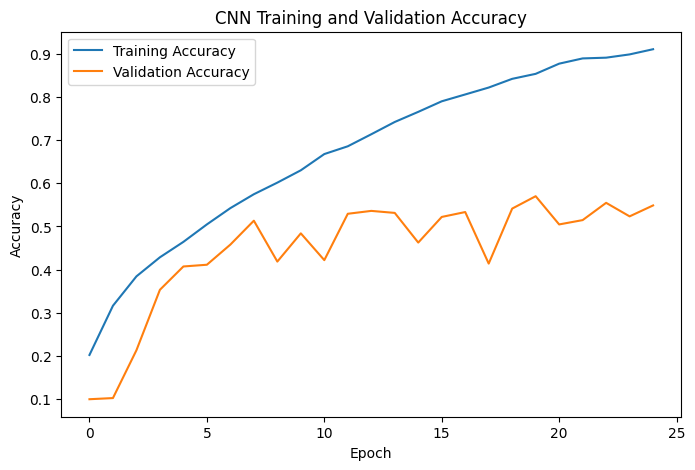

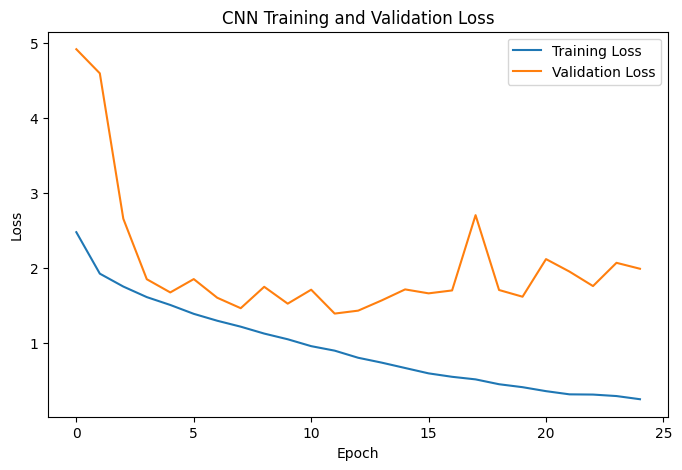

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step
              precision    recall  f1-score   support

   butterfly       0.68      0.83      0.75       150
         cat       0.42      0.56      0.48       150
     chicken       0.74      0.56      0.64       150
         cow       0.62      0.38      0.47       150
         dog       0.33      0.54      0.41       150
    elephant       0.56      0.61      0.59       150
       horse       0.45      0.60      0.51       150
       sheep       0.64      0.45      0.53       150
      spider       0.81      0.49      0.61       150
    squirrel       0.60      0.39      0.47       150

    accuracy                           0.54      1500
   macro avg       0.58      0.54      0.55      1500
weighted avg       0.58      0.54      0.55      1500



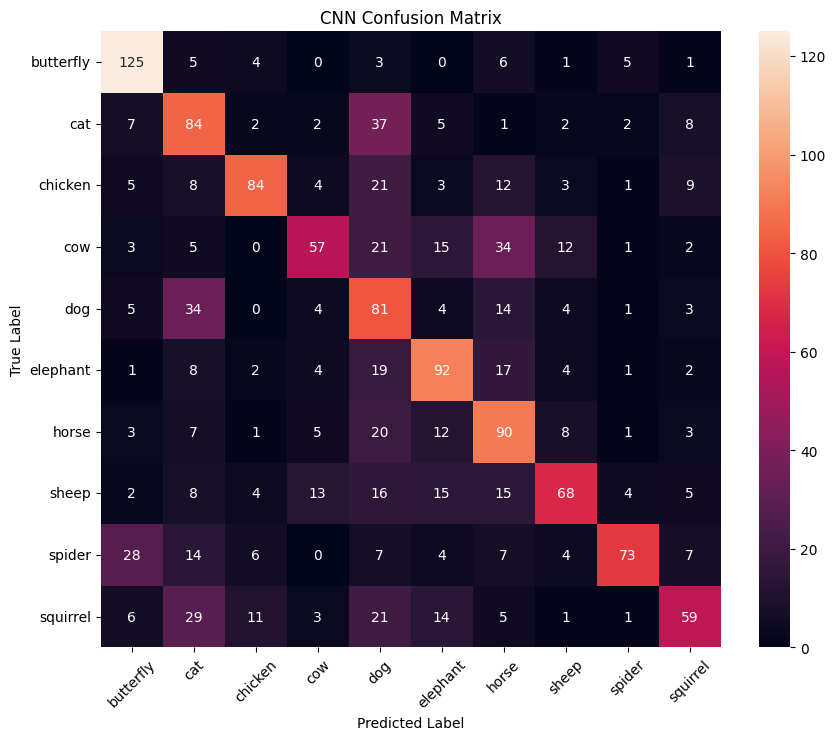

In [26]:
cnn_predictions = cnn_model.predict(X_test_small)
cnn_predicted_classes = np.argmax(cnn_predictions, axis=1)

print(classification_report(y_test, cnn_predicted_classes, target_names=class_names))

cnn_cm = confusion_matrix(y_test, cnn_predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [27]:
results = pd.DataFrame({
    "Model": ["MLP", "Random Forest", "CNN"],
    "Test Accuracy": [mlp_test_accuracy, rf_test_accuracy, cnn_test_accuracy]
})

results

,Model,Test Accuracy
0,MLP,0.158000
1,Random Forest,0.356667
2,CNN,0.542000


## Dimensionality reduction and clustering

Explore PCA and unsupervised classification with MiniBatch K-Means.


In [28]:
import numpy as np

X_all_flat = np.concatenate([X_train_flat, X_val_flat, X_test_flat], axis=0)
y_all = np.concatenate([y_train, y_val, y_test], axis=0)

print("All flattened images:", X_all_flat.shape)
print("All labels:", y_all.shape)

All flattened images: (10000, 3072)
All labels: (10000,)


In [29]:
from sklearn.decomposition import PCA

pca = PCA(n_components=100, random_state=42)
X_all_pca = pca.fit_transform(X_all_flat)

print("PCA feature shape:", X_all_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.sum())

PCA feature shape: (10000, 100)
Explained variance ratio: 0.77154964


In [30]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 16)

inertia_scores = []
silhouette_scores = []

for k in k_values:
    kmeans = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=512,
        n_init=10,
        max_iter=100
    )

    cluster_labels = kmeans.fit_predict(X_all_pca)

    inertia_scores.append(kmeans.inertia_)

    sil_score = silhouette_score(
        X_all_pca,
        cluster_labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(sil_score)

    print("k =", k, "Inertia =", kmeans.inertia_, "Silhouette =", sil_score)

k = 2 Inertia = 1363775.125 Silhouette = 0.21435653
k = 3 Inertia = 1226024.5 Silhouette = 0.122408465
k = 4 Inertia = 1169419.375 Silhouette = 0.11215419
k = 5 Inertia = 1126892.0 Silhouette = 0.08864494
k = 6 Inertia = 1094598.0 Silhouette = 0.07323143
k = 7 Inertia = 1074781.125 Silhouette = 0.06671406
k = 8 Inertia = 1056994.125 Silhouette = 0.0676978
k = 9 Inertia = 1041920.5 Silhouette = 0.05939261
k = 10 Inertia = 1035576.3125 Silhouette = 0.052600097
k = 11 Inertia = 1009708.75 Silhouette = 0.051120218
k = 12 Inertia = 1009413.625 Silhouette = 0.05550032
k = 13 Inertia = 999342.5 Silhouette = 0.04769513
k = 14 Inertia = 979224.0625 Silhouette = 0.049927946
k = 15 Inertia = 971623.125 Silhouette = 0.04711391


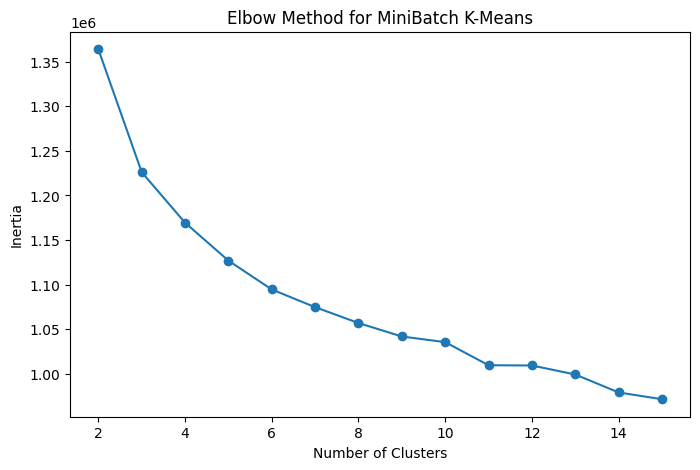

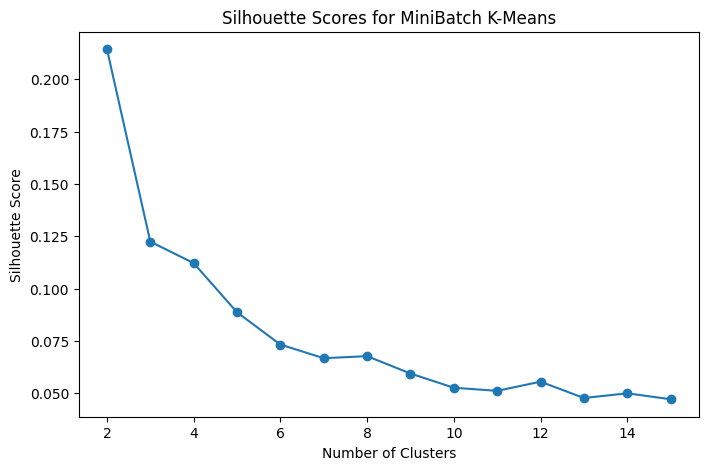

Best k by silhouette score: 2


In [31]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_scores, marker="o")
plt.title("Elbow Method for MiniBatch K-Means")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Scores for MiniBatch K-Means")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.show()

best_k = list(k_values)[np.argmax(silhouette_scores)]
print("Best k by silhouette score:", best_k)

In [32]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, confusion_matrix
from scipy.optimize import linear_sum_assignment
import seaborn as sns

def clustering_accuracy(y_true, y_cluster):
    y_true = np.asarray(y_true)
    y_cluster = np.asarray(y_cluster)

    true_labels = np.unique(y_true)
    cluster_labels = np.unique(y_cluster)

    matrix = np.zeros((len(cluster_labels), len(true_labels)), dtype=np.int64)

    for i, cluster in enumerate(cluster_labels):
        for j, label in enumerate(true_labels):
            matrix[i, j] = np.sum((y_cluster == cluster) & (y_true == label))

    row_ind, col_ind = linear_sum_assignment(-matrix)

    accuracy = matrix[row_ind, col_ind].sum() / len(y_true)

    cluster_to_label = {
        cluster_labels[row]: true_labels[col]
        for row, col in zip(row_ind, col_ind)
    }

    return accuracy, cluster_to_label

kmeans_10 = MiniBatchKMeans(
    n_clusters=num_classes,
    random_state=42,
    batch_size=512,
    n_init=10,
    max_iter=100
)

cluster_10_labels = kmeans_10.fit_predict(X_all_pca)

cluster_acc, cluster_mapping = clustering_accuracy(y_all, cluster_10_labels)
ari_score = adjusted_rand_score(y_all, cluster_10_labels)
nmi_score = normalized_mutual_info_score(y_all, cluster_10_labels)

print("MiniBatch K-Means Clustering Accuracy:", cluster_acc)
print("Adjusted Rand Index:", ari_score)
print("Normalized Mutual Information:", nmi_score)
print("Cluster to class mapping:", cluster_mapping)

MiniBatch K-Means Clustering Accuracy: 0.1755
Adjusted Rand Index: 0.017769882996225995
Normalized Mutual Information: 0.04274197290044043
Cluster to class mapping: {np.int32(0): np.int32(8), np.int32(1): np.int32(6), np.int32(2): np.int32(9), np.int32(3): np.int32(7), np.int32(4): np.int32(3), np.int32(5): np.int32(1), np.int32(6): np.int32(4), np.int32(7): np.int32(2), np.int32(8): np.int32(5), np.int32(9): np.int32(0)}


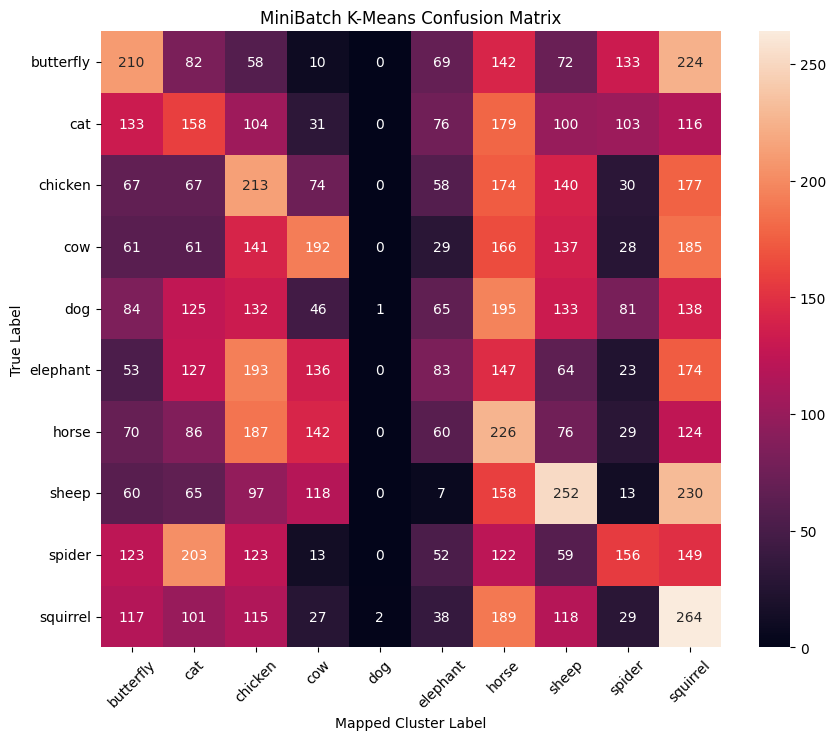

In [33]:
mapped_cluster_predictions = np.array([
    cluster_mapping[cluster]
    for cluster in cluster_10_labels
])

cluster_cm = confusion_matrix(y_all, mapped_cluster_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cluster_cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MiniBatch K-Means Confusion Matrix")
plt.xlabel("Mapped Cluster Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [34]:
clustering_results = pd.DataFrame({
    "Method": ["MiniBatch K-Means with PCA"],
    "Number of Clusters": [num_classes],
    "Clustering Accuracy": [cluster_acc],
    "Adjusted Rand Index": [ari_score],
    "Normalized Mutual Information": [nmi_score]
})

clustering_results

,Method,Number of Clusters,Clustering Accuracy,Adjusted Rand Index,Normalized Mutual Information
0,MiniBatch K-Means with PCA,10,0.1755,0.01777,0.042742


## Improved CNN experiment

Try data augmentation, early stopping and learning rate scheduling.


In [35]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    RandomFlip,
    RandomRotation,
    RandomZoom
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [36]:
improved_cnn_model = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),
    RandomRotation(0.10),
    RandomZoom(0.10),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dropout(0.5),
    Dense(256, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

improved_cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

improved_cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 815,914 (3.11 MB)

 Trainable params: 815,018 (3.11 MB)

 Non-trainable params: 896 (3.50 KB)

In [37]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

improved_cnn_history = improved_cnn_model.fit(
    X_train_small,
    y_train_cat,
    validation_data=(X_val_small, y_val_cat),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.2010 - loss: 2.4930 - val_accuracy: 0.1000 - val_loss: 2.6927 - learning_rate: 0.0010
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.2614 - loss: 2.0638 - val_accuracy: 0.1067 - val_loss: 2.9641 - learning_rate: 0.0010
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.2980 - loss: 1.9860 - val_accuracy: 0.2120 - val_loss: 2.3567 - learning_rate: 0.0010
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.3307 - loss: 1.8937 - val_accuracy: 0.2580 - val_loss: 2.2045 - learning_rate: 0.0010
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.3559 - loss: 1.8126 - val_accuracy: 0.3733 - val_loss: 1.7964 - learning_rate: 0.0010
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.3700 - loss: 1.7723 - val_accuracy: 0.4093 - val_loss: 1.6873 - learning_rate: 0.0010
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.3910 - loss: 1

In [38]:
improved_cnn_test_loss, improved_cnn_test_accuracy = improved_cnn_model.evaluate(
    X_test_small,
    y_test_cat,
    verbose=0
)

print("Improved CNN Test Loss:", improved_cnn_test_loss)
print("Improved CNN Test Accuracy:", improved_cnn_test_accuracy)

Improved CNN Test Loss: 1.4992525577545166
Improved CNN Test Accuracy: 0.4753333330154419


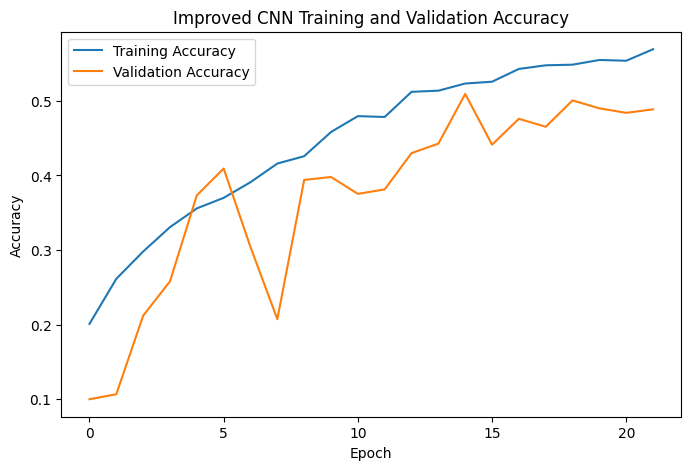

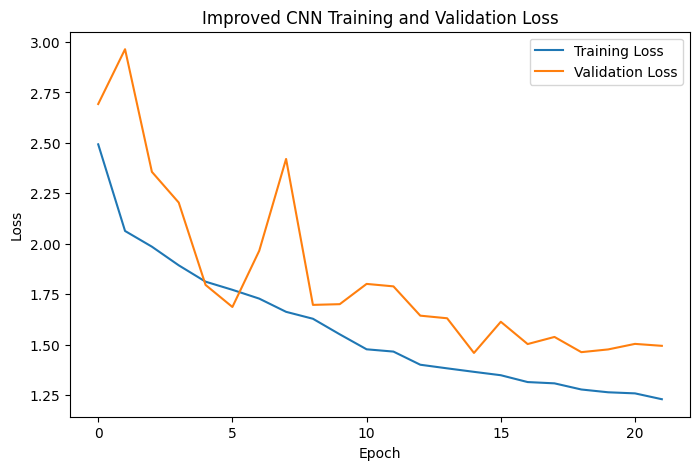

In [39]:
plt.figure(figsize=(8, 5))
plt.plot(improved_cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(improved_cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Improved CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(improved_cnn_history.history["loss"], label="Training Loss")
plt.plot(improved_cnn_history.history["val_loss"], label="Validation Loss")
plt.title("Improved CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
              precision    recall  f1-score   support

   butterfly       0.56      0.87      0.68       150
         cat       0.52      0.22      0.31       150
     chicken       0.62      0.62      0.62       150
         cow       0.35      0.44      0.39       150
         dog       0.34      0.12      0.18       150
    elephant       0.56      0.49      0.52       150
       horse       0.35      0.46      0.40       150
       sheep       0.35      0.52      0.42       150
      spider       0.59      0.58      0.58       150
    squirrel       0.56      0.43      0.49       150

    accuracy                           0.48      1500
   macro avg       0.48      0.48      0.46      1500
weighted avg       0.48      0.48      0.46      1500



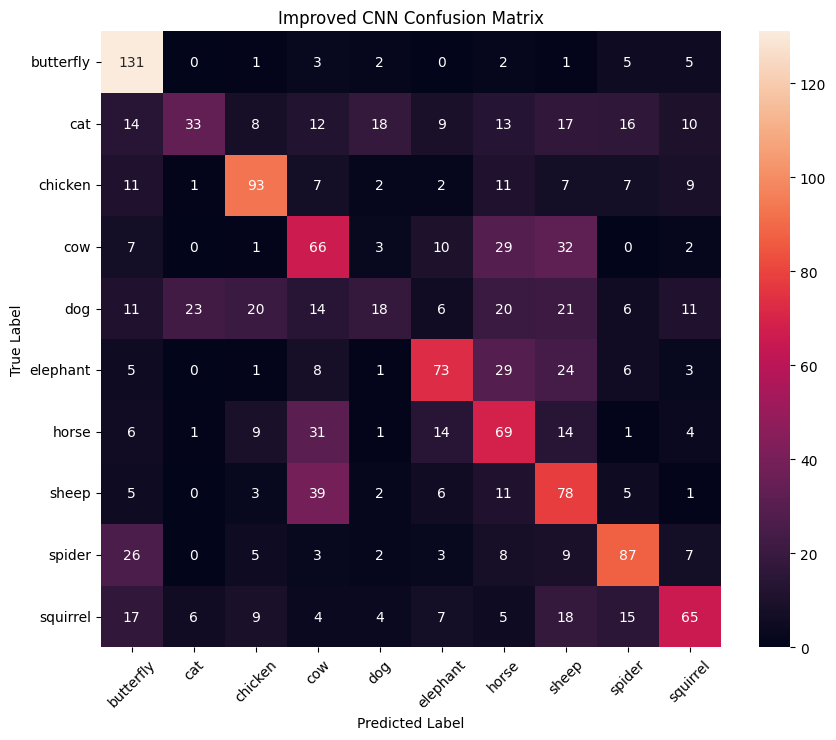

In [40]:
improved_cnn_predictions = improved_cnn_model.predict(X_test_small)
improved_cnn_predicted_classes = np.argmax(improved_cnn_predictions, axis=1)

print(classification_report(
    y_test,
    improved_cnn_predicted_classes,
    target_names=class_names
))

improved_cnn_cm = confusion_matrix(y_test, improved_cnn_predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(
    improved_cnn_cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Improved CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

## Final model comparison

Summarise results across the supervised learning approaches.


In [41]:
results = pd.DataFrame({
    "Model": [
        "MLP",
        "Random Forest",
        "CNN",
        "Improved CNN"
    ],
    "Test Accuracy": [
        mlp_test_accuracy,
        rf_test_accuracy,
        cnn_test_accuracy,
        improved_cnn_test_accuracy
    ]
})

results

,Model,Test Accuracy
0,MLP,0.158000
1,Random Forest,0.356667
2,CNN,0.542000
3,Improved CNN,0.475333
